<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/deteccion_casco_motociclistas_VF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏍️ Detección de motociclistas **sin casco** con YOLO-World + Supervision
### Laboratorio de Códigos

En este notebook construimos un sistema que:

1. Detecta **personas**, **motocicletas** y **cascos** con **YOLO-World** (detección *zero-shot*: le decimos qué buscar con texto, sin entrenar).
2. Decide quién es **conductor o pasajero** de una moto (no un peatón).
3. Revisa la **zona de la cabeza** de cada motociclista para saber si lleva casco.
4. Marca en **verde** a quien sí lo lleva y en **rojo** a quien no.
5. En video, **sigue** a cada motociclista con ByteTrack y **cuenta infractores únicos**.

> 💡 Activa la GPU: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*.

## 1. Instalación

In [ ]:
!pip install -q ultralytics supervision trackers transformers

## 2. Importaciones

In [ ]:
import os
import cv2
import numpy as np
import supervision as sv
import matplotlib.pyplot as plt
from collections import defaultdict, deque
from ultralytics import YOLOWorld
from trackers import ByteTrackTracker

print("Supervision:", sv.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Supervision: 0.31.7


## 3. Cargar YOLO-World y definir qué buscar

YOLO-World entiende texto gracias a CLIP. Le damos una lista de clases **en inglés**.

⚠️ **Truco clave — clases "rivales":** si solo le damos `helmet`, YOLO-World tiende a llamar *casco* a **cualquier cabeza redonda** (cabello, gorra, capucha), porque es la opción más parecida que tiene. Por eso agregamos clases que **compiten** con el casco: `head`, `hair`, `cap`, `face`. Así, una cabeza descubierta tiene a dónde ir.

In [ ]:
model = YOLOWorld("yolov8x-worldv2.pt")   # usa "yolov8s-worldv2.pt" si quieres más velocidad

CLASES = ["person", "motorcycle",
          "helmet", "motorcycle helmet",          # casco
          "head", "hair", "cap", "face"]          # rivales: cabeza SIN casco
model.set_classes(CLASES)

ID_PERSONA, ID_MOTO, ID_CASCO, ID_CABEZA = 0, 1, 2, 4
IDS_CASCO = [2, 3]           # se unen en ID_CASCO
IDS_CABEZA = [4, 5, 6, 7]    # se unen en ID_CABEZA

# Umbral de confianza por clase
UMBRAL = {ID_PERSONA: 0.25, ID_MOTO: 0.25, ID_CASCO: 0.15, ID_CABEZA: 0.10}

requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 37 packages in 700ms
Prepared 2 packages in 2.63s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|███████████████████████████████████████| 338M/338M [00:16<00:00, 21.0MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


## 4. Cargar una imagen de prueba

Sube una foto de tráfico con motociclistas (o pega la URL de una imagen).

Saving descarga (4).png to descarga (4).png


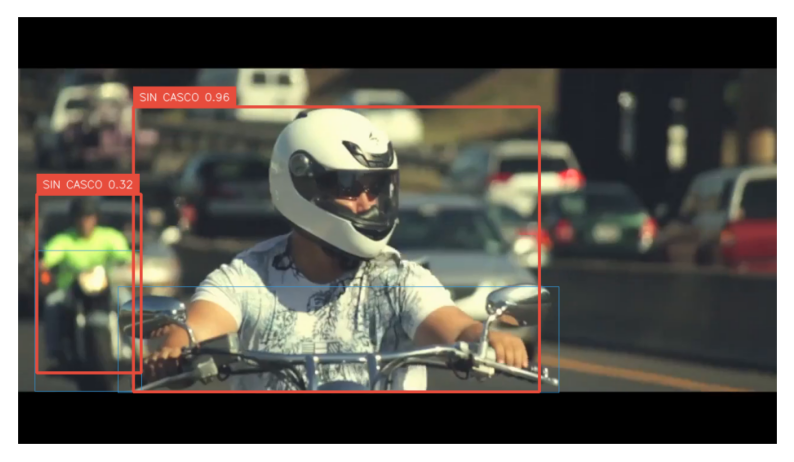

In [ ]:
from google.colab import files

subidos = files.upload()                  # elige una imagen .jpg / .png
RUTA_IMAGEN = list(subidos.keys())[0]

# Alternativa con URL:
# !wget -q -O motos.jpg "PEGA_AQUI_LA_URL" ; RUTA_IMAGEN = "motos.jpg"

imagen = cv2.imread(RUTA_IMAGEN)
plt.figure(figsize=(10, 6)); plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)); plt.axis("off");

## 5. Detectar y limpiar

1. Predecimos con un umbral bajo.
2. Unimos las frases de casco en `ID_CASCO` y las rivales en `ID_CABEZA`.
3. Aplicamos el umbral de cada clase.
4. **Competencia casco vs. cabeza:** si una caja de *casco* y una de *cabeza* están en el mismo lugar, solo sobrevive la de mayor confianza (NMS sin distinguir clase).

In [ ]:
def detectar(frame, conf_min=0.05):
    resultado = model.predict(frame, conf=conf_min, verbose=False)[0]
    det = sv.Detections.from_ultralytics(resultado)
    if len(det) == 0:
        return det

    # Unir frases
    det.class_id = np.where(np.isin(det.class_id, IDS_CASCO), ID_CASCO, det.class_id)
    det.class_id = np.where(np.isin(det.class_id, IDS_CABEZA), ID_CABEZA, det.class_id)

    # Umbral por clase
    umbrales = np.array([UMBRAL[c] for c in det.class_id])
    det = det[det.confidence >= umbrales]

    # Personas y motos: NMS normal. Casco vs cabeza: compiten entre sí
    es_cabeza = np.isin(det.class_id, [ID_CASCO, ID_CABEZA])
    resto = det[~es_cabeza].with_nms(threshold=0.5, class_agnostic=False)
    cabezas = det[es_cabeza].with_nms(threshold=0.3, class_agnostic=True)
    return sv.Detections.merge([resto, cabezas])

det = detectar(imagen)
print(f"Personas: {(det.class_id == ID_PERSONA).sum()} | "
      f"Motos: {(det.class_id == ID_MOTO).sum()} | "
      f"Cascos: {(det.class_id == ID_CASCO).sum()} | "
      f"Cabezas sin casco: {(det.class_id == ID_CABEZA).sum()}")

Personas: 2 | Motos: 2 | Cascos: 2 | Cabezas sin casco: 0


## 6. La lógica: ¿quién va en moto y quién lleva casco?

YOLO-World no sabe qué es *"persona sin casco"*, así que lo resolvemos con **geometría**:

**¿Es motociclista?** Una persona es conductor/pasajero si:
- una buena parte de su caja se **traslapa** con una moto,
- el **centro horizontal** de la persona cae dentro de la moto, y
- su parte **superior está por encima** de la moto (va sentada arriba, no al lado).

**¿Lleva casco? (versión estricta)** Un casco solo cuenta para una persona si:
- al menos el **60 % del casco** está dentro de su zona de cabeza (el 25 % superior de su caja),
- su **tamaño es razonable** respecto a la persona (ni una mancha diminuta ni algo más ancho que ella), y
- **cada casco se asigna a una sola persona**: la que mejor lo contiene. Esto evita que el casco del conductor "se le preste" al pasajero sin casco que va pegado detrás.


In [ ]:
def area(caja):
    return max(0, caja[2] - caja[0]) * max(0, caja[3] - caja[1])

def interseccion(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    return max(0, x2 - x1) * max(0, y2 - y1)

def es_motociclista(persona, motos, min_traslape=0.20):
    cx = (persona[0] + persona[2]) / 2
    for moto in motos:
        traslape = interseccion(persona, moto) / (area(persona) + 1e-6)
        centrado = moto[0] <= cx <= moto[2]
        arriba = persona[1] < moto[1]
        if traslape >= min_traslape and centrado and arriba:
            return True
    return False

def zona_cabeza(persona, frac=0.25, margen=0.05):
    x1, y1, x2, y2 = persona
    w, h = x2 - x1, y2 - y1
    return np.array([x1 - margen * w, y1 - margen * h, x2 + margen * w, y1 + frac * h])

# Parámetros de la asignación casco → persona
MIN_DENTRO = 0.40                 # fracción del casco que debe caer en la zona de cabeza
ANCHO_REL = (0.10, 0.90)          # ancho del casco / ancho de la persona

def asignar_cascos(riders_xyxy, cascos_xyxy):
    tiene = np.zeros(len(riders_xyxy), dtype=bool)
    for c in cascos_xyxy:
        mejor, mejor_score = None, 0
        for i, p in enumerate(riders_xyxy):
            cab = zona_cabeza(p)
            dentro = interseccion(c, cab) / (area(c) + 1e-6)
            ancho_rel = (c[2] - c[0]) / (p[2] - p[0] + 1e-6)
            # el borde superior del casco cae en la zona de cabeza
            tope_en_cabeza = cab[1] <= c[1] <= cab[3] and p[0] <= (c[0] + c[2]) / 2 <= p[2]
            if (dentro >= MIN_DENTRO or tope_en_cabeza) and ANCHO_REL[0] <= ancho_rel <= ANCHO_REL[1]:
                if dentro > mejor_score:
                    mejor, mejor_score = i, dentro
        if mejor is not None:
            tiene[mejor] = True
    return tiene

## 6.1 Segunda opinión con CLIP 🧠

Aunque YOLO diga "casco", le pedimos a **CLIP** que mire **solo el recorte de la cabeza** y elija entre descripciones:

- ✅ *"una persona con casco de motocicleta"*, *"una persona con casco integral"*
- ❌ *"cabeza descubierta con cabello"*, *"persona con gorra"*, *"cara sin casco"*

Sumamos las probabilidades del lado ✅. Una persona solo queda **CON CASCO** si YOLO **y** CLIP están de acuerdo (`MODO = "ambos"`). Esto es lo que más reduce los falsos "con casco".

In [ ]:
import torch
from transformers import CLIPModel, CLIPProcessor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLIP_ID = "openai/clip-vit-large-patch14"
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)

TEXTOS_CASCO = ["a photo of a person wearing a motorcycle helmet",
                "a photo of a person wearing a full face helmet"]
TEXTOS_SIN = ["a photo of a person's bare head with hair",
              "a photo of a person wearing a baseball cap",
              "a photo of a person's face without a helmet"]

def recorte_cabeza(frame, persona, frac=0.30, margen=0.10):
    h_img, w_img = frame.shape[:2]
    x1, y1, x2, y2 = zona_cabeza(persona, frac=frac, margen=margen).astype(int)
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w_img, x2), min(h_img, y2)
    return cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)

@torch.no_grad()
def prob_casco_clip(frame, riders_xyxy):
    if len(riders_xyxy) == 0:
        return np.array([])
    recortes = [recorte_cabeza(frame, p) for p in riders_xyxy]
    entradas = clip_proc(text=TEXTOS_CASCO + TEXTOS_SIN, images=recortes,
                         return_tensors="pt", padding=True).to(DEVICE)
    probs = clip_model(**entradas).logits_per_image.softmax(dim=1).cpu().numpy()
    return probs[:, :len(TEXTOS_CASCO)].sum(axis=1)

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## 6.2 Decisión final

- `MODO = "ambos"` → CON CASCO solo si YOLO encontró casco **y** CLIP da ≥ `UMBRAL_CLIP` (recomendado).
- `MODO = "clip"` → decide solo CLIP (útil si YOLO no ve cascos lejanos).
- `MODO = "yolo"` → comportamiento original.

In [ ]:
MODO = "ambos"
UMBRAL_CLIP = 0.60
UMBRAL_CLIP_SOLO = 0.90

CON_CASCO, SIN_CASCO = 0, 1

def analizar_motociclistas(det, frame):
    """Devuelve solo los motociclistas, con class_id = CON_CASCO / SIN_CASCO
    y la probabilidad de CLIP en riders.data["p_casco"]."""
    personas = det[det.class_id == ID_PERSONA]
    motos = det.xyxy[det.class_id == ID_MOTO]
    cascos = det.xyxy[det.class_id == ID_CASCO]

    mask = np.array([es_motociclista(p, motos) for p in personas.xyxy], dtype=bool)
    riders = personas[mask] if len(personas) else personas
    if len(riders) == 0:
        return riders

    yolo = asignar_cascos(riders.xyxy, cascos)
    if MODO == "yolo":
        p_clip = yolo.astype(float)
        decision = yolo
    else:
        p_clip = prob_casco_clip(frame, riders.xyxy)
        decision = (p_clip >= UMBRAL_CLIP) if MODO == "clip" else ((yolo & (p_clip >= UMBRAL_CLIP)) | (p_clip >= UMBRAL_CLIP_SOLO))

    riders.class_id = np.where(decision, CON_CASCO, SIN_CASCO)
    riders.data["p_casco"] = p_clip
    riders.data["yolo_casco"] = yolo
    return riders

motociclistas = analizar_motociclistas(det, imagen)
print(f"Motociclistas: {len(motociclistas)} | "
      f"Con casco: {(motociclistas.class_id == CON_CASCO).sum()} | "
      f"Sin casco: {(motociclistas.class_id == SIN_CASCO).sum()}")

Motociclistas: 2 | Con casco: 1 | Sin casco: 1


## 7. Dibujar el resultado

Verde = con casco · Rojo = **sin casco** · Azul tenue = motos detectadas

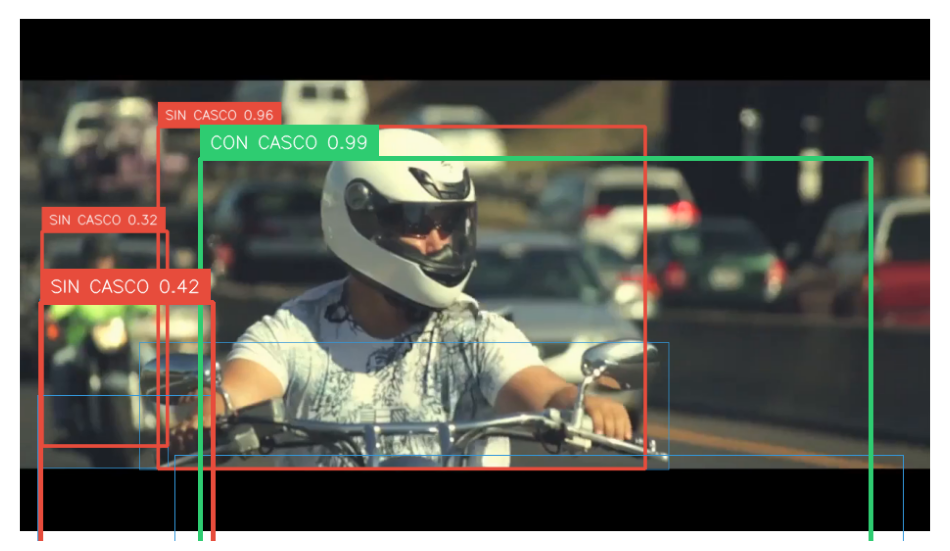

In [ ]:
PALETA = sv.ColorPalette([sv.Color.from_hex("#2ECC71"), sv.Color.from_hex("#E74C3C")])
ETIQUETAS = {CON_CASCO: "CON CASCO", SIN_CASCO: "SIN CASCO"}

caja_riders = sv.BoxAnnotator(color=PALETA, thickness=3, color_lookup=sv.ColorLookup.CLASS)
texto_riders = sv.LabelAnnotator(color=PALETA, text_color=sv.Color.WHITE,
                                 text_scale=0.6, color_lookup=sv.ColorLookup.CLASS)
caja_motos = sv.BoxAnnotator(color=sv.Color.from_hex("#3498DB"), thickness=1)

def anotar(frame, det, riders, etiquetas=None):
    out = frame.copy()
    out = caja_motos.annotate(out, det[det.class_id == ID_MOTO])
    out = caja_riders.annotate(out, riders)
    if etiquetas is None:
        etiquetas = [f"{ETIQUETAS[c]} {p:.2f}" for c, p in zip(riders.class_id, riders.data.get("p_casco", np.zeros(len(riders))))]
    return texto_riders.annotate(out, riders, labels=etiquetas)

resultado = anotar(imagen, det, motociclistas)
sv.plot_image(resultado, size=(12, 8))

### 🔍 Depuración: ver todo lo que detectó YOLO-World

Revisa qué vio el modelo: cajas de **casco** vs **cabeza** (las rivales) y en amarillo la zona de cabeza que se revisa.

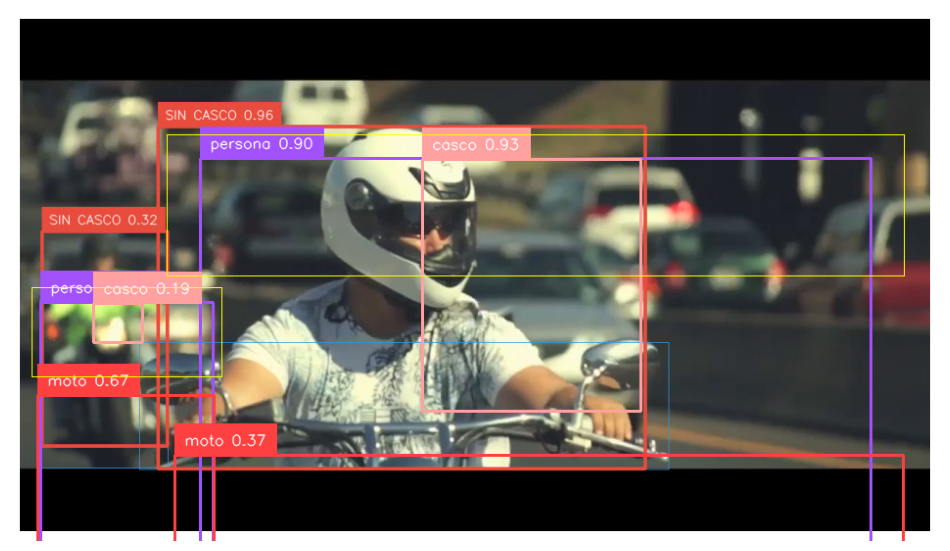

In [ ]:
nombres = {ID_PERSONA: "persona", ID_MOTO: "moto", ID_CASCO: "casco", ID_CABEZA: "cabeza"}
etq = [f"{nombres[c]} {p:.2f}" for c, p in zip(det.class_id, det.confidence)]
img_debug = sv.BoxAnnotator(thickness=2).annotate(imagen.copy(), det)
img_debug = sv.LabelAnnotator(text_scale=0.5).annotate(img_debug, det, labels=etq)

# Dibujar las zonas de cabeza que se revisan
for p in det.xyxy[det.class_id == ID_PERSONA]:
    x1, y1, x2, y2 = zona_cabeza(p).astype(int)
    cv2.rectangle(img_debug, (x1, y1), (x2, y2), (0, 255, 255), 1)

sv.plot_image(img_debug, size=(12, 8))

### 🔍 Depuración: ¿qué opinan YOLO y CLIP de cada cabeza?

Cada recorte muestra si YOLO le asignó casco y la probabilidad de CLIP. Úsalo para **calibrar `UMBRAL_CLIP`**: busca un valor que separe a los que sí llevan casco de los que no.

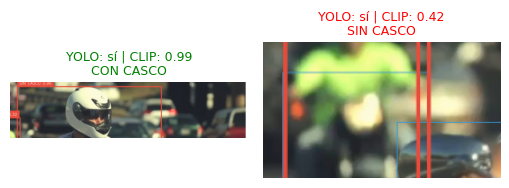

In [ ]:
if len(motociclistas):
    n = len(motociclistas)
    fig, ejes = plt.subplots(1, n, figsize=(2.6 * n, 3.2))
    ejes = np.atleast_1d(ejes)
    for ax, p, pc, y, c in zip(ejes, motociclistas.xyxy, motociclistas.data["p_casco"],
                               motociclistas.data["yolo_casco"], motociclistas.class_id):
        ax.imshow(recorte_cabeza(imagen, p))
        ax.set_title(f"YOLO: {'sí' if y else 'no'} | CLIP: {pc:.2f}\n{ETIQUETAS[c]}",
                     fontsize=9, color="green" if c == CON_CASCO else "red")
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 8. Video: seguimiento y conteo de infractores

En video, la detección del casco puede **parpadear** de un cuadro a otro. Para evitar falsas alarmas:

- Seguimos a cada motociclista con **ByteTrack** (paquete `trackers` de Roboflow), que le asigna un ID.
- Guardamos el historial de los últimos cuadros y decidimos por **mayoría de votos**.
- Un ID cuenta como infractor solo si lleva **varios cuadros** marcado sin casco.
- Guardamos una **captura** de cada infractor.

In [ ]:
subidos = files.upload()                  # sube un video .mp4
RUTA_VIDEO = list(subidos.keys())[0]
RUTA_SALIDA = "motos_casco_resultado.mp4"
os.makedirs("infractores", exist_ok=True)

info = sv.VideoInfo.from_video_path(RUTA_VIDEO)
print(info)

Saving 62-135732059_medium.mp4 to 62-135732059_medium.mp4
VideoInfo(width=1280, height=720, fps=23.976023976023978, total_frames=599)


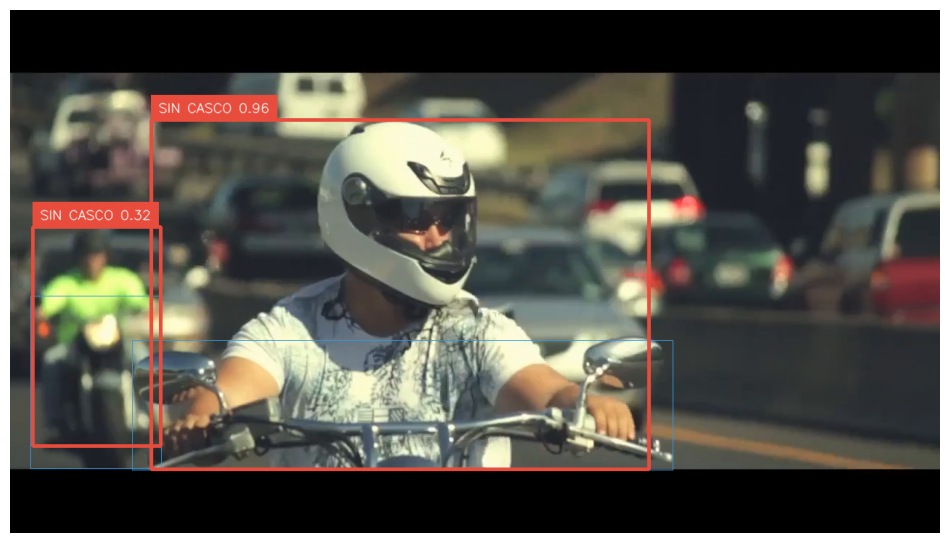

In [ ]:
SEGUNDO = 15   # cambia al segundo en que aparece la persona
info = sv.VideoInfo.from_video_path(RUTA_VIDEO)
gen = sv.get_video_frames_generator(RUTA_VIDEO, start=int(SEGUNDO * info.fps))
imagen = next(gen)

det = detectar(imagen)
motociclistas = analizar_motociclistas(det, imagen)
sv.plot_image(anotar(imagen, det, motociclistas), size=(12, 8))

In [ ]:
tracker = ByteTrackTracker(frame_rate=info.fps)
historial = defaultdict(lambda: deque(maxlen=15))   # votos por ID
MIN_CUADROS_INFRACCION = 8
infractores = set()
vistos = set()

def procesar(frame, idx):
    det = detectar(frame)
    riders = analizar_motociclistas(det, frame)
    riders = tracker.update(riders)
    if len(riders):
        riders = riders[riders.tracker_id != -1]   # ignora tracks aún no confirmados

    etiquetas = []
    estados = []
    for caja, tid, estado in zip(riders.xyxy, riders.tracker_id, riders.class_id):
        historial[tid].append(estado)
        votos_sin = sum(1 for e in historial[tid] if e == SIN_CASCO)
        final = SIN_CASCO if votos_sin > len(historial[tid]) / 2 else CON_CASCO
        estados.append(final)
        vistos.add(tid)

        if final == SIN_CASCO and votos_sin >= MIN_CUADROS_INFRACCION and tid not in infractores:
            infractores.add(tid)
            x1, y1, x2, y2 = caja.astype(int)
            cv2.imwrite(f"infractores/id_{tid}.jpg", frame[max(0, y1):y2, max(0, x1):x2])

        etiquetas.append(f"#{tid} {ETIQUETAS[final]}")

    if len(riders):
        riders.class_id = np.array(estados)
    out = anotar(frame, det, riders, etiquetas)

    # Panel con el conteo
    cv2.rectangle(out, (10, 10), (330, 85), (0, 0, 0), -1)
    cv2.putText(out, f"Motociclistas: {len(vistos)}", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    cv2.putText(out, f"Sin casco: {len(infractores)}", (20, 72),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (60, 76, 231), 2)
    return out

sv.process_video(source_path=RUTA_VIDEO, target_path=RUTA_SALIDA, callback=procesar,
                 show_progress=True)
print(f"✅ Listo. Motociclistas únicos: {len(vistos)} | Infractores: {len(infractores)}")

Processing video:   0%|          | 0/599 [00:00<?, ?it/s]

✅ Listo. Motociclistas únicos: 8 | Infractores: 7


## 9. Ver las capturas de infractores

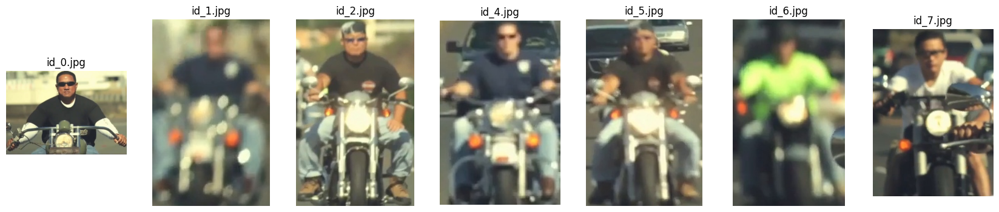

In [ ]:
import glob
capturas = sorted(glob.glob("infractores/*.jpg"))
if capturas:
    n = len(capturas)
    fig, ejes = plt.subplots(1, n, figsize=(3 * n, 4))
    ejes = np.atleast_1d(ejes)
    for ax, ruta in zip(ejes, capturas):
        ax.imshow(cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB))
        ax.set_title(os.path.basename(ruta)); ax.axis("off")
    plt.show()
else:
    print("No se detectaron infractores 🎉")

## 10. Descargar el video procesado

In [ ]:
files.download(RUTA_SALIDA)

In [ ]:
import os
from IPython.display import HTML
from base64 import b64encode

# Convertir el video a formato compatible con HTML5 (H.264)
print("Codificando video a H.264 para su visualización...")
os.system("ffmpeg -y -i motos_casco_resultado.mp4 -vcodec libx264 -f mp4 output_web.mp4 -loglevel quiet")

# Leer y mostrar el video convertido
mp4 = open('output_web.mp4','rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

HTML(f"""
<video width=800 controls>
      <source src="{data_url}" type="video/mp4">
</video>
""")

Codificando video a H.264 para su visualización...


**Uso responsable**: este es un proyecto educativo. YOLO-World zero-shot puede equivocarse; no lo uses para sancionar a nadie sin revisión humana y respeta la privacidad de las personas que aparecen en los videos.